In [1]:
# Experiment 08 — Quantum Entanglement and Teleportation

In [2]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator
from qiskit import transpile
import numpy as np

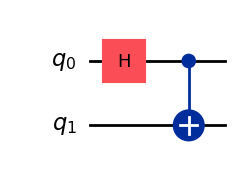

Bell Statevector: [0.70710678+0.j 0.        +0.j 0.        +0.j 0.70710678+0.j]
Probabilities: {np.str_('00'): np.float64(0.4999999999999999), np.str_('11'): np.float64(0.4999999999999999)}


In [6]:
# Create a two-qubit circuit
bell = QuantumCircuit(2)

# Apply Hadamard and CNOT gates
bell.h(0)
bell.cx(0, 1)

# Display the circuit
display(bell.draw("mpl"))

# Show the entangled state
bell_state = Statevector.from_instruction(bell)

print("Bell Statevector:", bell_state.data)
print("Probabilities:", bell_state.probabilities_dict())

Bell State Counts: {'00': 521, '11': 503}


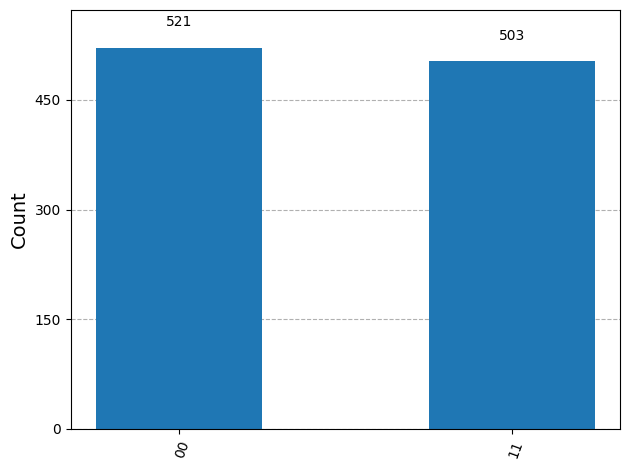

In [7]:
# Create a measurement circuit
bell_measure = bell.copy()
bell_measure.measure_all()

# Run the circuit using AerSimulator
simulator = AerSimulator()
result = simulator.run(
    transpile(bell_measure, simulator),
    shots=1024,
    seed_simulator=42
).result()

counts = result.get_counts()

print("Bell State Counts:", counts)
display(plot_histogram(counts))

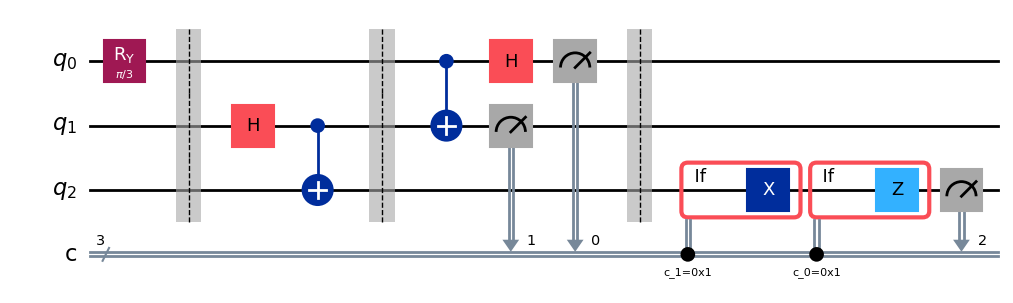

In [8]:
# Create a circuit with three qubits and three classical bits
teleport = QuantumCircuit(3, 3)

# Prepare the state to teleport on qubit 0
teleport.ry(np.pi / 3, 0)

teleport.barrier()

# Create an entangled pair between qubits 1 and 2
teleport.h(1)
teleport.cx(1, 2)

teleport.barrier()

# Perform Bell measurement operations
teleport.cx(0, 1)
teleport.h(0)

# Measure Alice's qubits
teleport.measure(0, 0)
teleport.measure(1, 1)

teleport.barrier()

# Apply corrections to Bob's qubit
with teleport.if_test((teleport.clbits[1], 1)):
    teleport.x(2)

with teleport.if_test((teleport.clbits[0], 1)):
    teleport.z(2)

# Measure the teleported qubit
teleport.measure(2, 2)

# Display the circuit
display(teleport.draw("mpl"))

Teleportation Counts: {'111': 76, '000': 182, '001': 185, '011': 177, '010': 212, '100': 57, '110': 66, '101': 69}


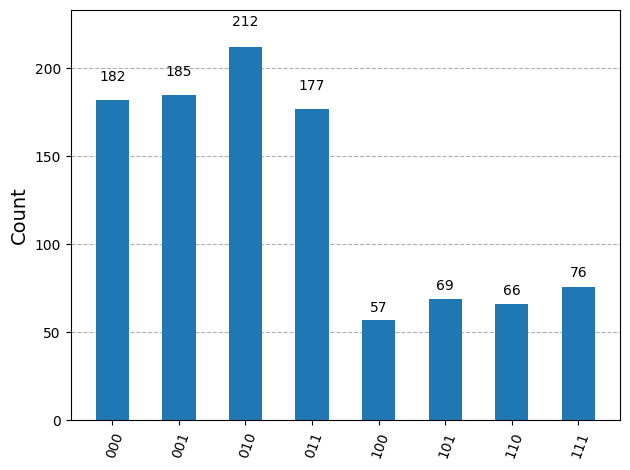

In [9]:
# Run the teleportation circuit
simulator = AerSimulator()

compiled = transpile(teleport, simulator)

result = simulator.run(
    compiled,
    shots=1024,
    seed_simulator=42
).result()

counts = result.get_counts()

print("Teleportation Counts:", counts)

# Display the measurement histogram
display(plot_histogram(counts))

Original State: [0.8660254+0.j 0.5      +0.j]
Original Probabilities: {np.str_('0'): np.float64(0.7500000000000001), np.str_('1'): np.float64(0.24999999999999994)}

Bob's Measurement Counts: {'0': 756, '1': 268}
Bob's Probabilities: {'0': 0.73828125, '1': 0.26171875}


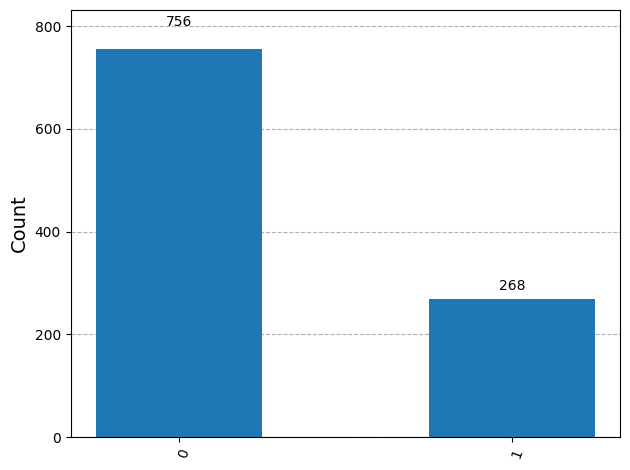

In [10]:
# Calculate the original state's probabilities
original = QuantumCircuit(1)
original.ry(np.pi / 3, 0)

original_state = Statevector.from_instruction(original)

print("Original State:", original_state.data)
print("Original Probabilities:", original_state.probabilities_dict())

# Extract Bob's measurement result from each bitstring
bob_counts = {"0": 0, "1": 0}

for bits, count in counts.items():
    bob_counts[bits[0]] += count

print("\nBob's Measurement Counts:", bob_counts)

# Compare the probabilities
print("Bob's Probabilities:", {
    bit: count / 1024 for bit, count in bob_counts.items()
})

display(plot_histogram(bob_counts))